# XGBoost: calcification and mass classification

Predict **malignant (1)** versus **benign (0)** from CSV annotations. Both benign pathology categories map to 0. These models use recorded features, not mammogram pixels. Each row represents an annotation/view, so reported metrics are row-level rather than patient-level.

Run the working cells in order. Patient groups stay separate during validation. Preprocessing learns from each training portion only. Development experiments compare features and thresholds; the final section retrains on the supplied training sets and evaluates the reserved test sets. The selected threshold of 0.3 prioritizes recall at the cost of more false positives.

**Run-order note:** the final test cell uses `average_precision_score` and `ConfusionMatrixDisplay`, imported in the later original-validation cell. A fresh top-to-bottom run needs those imports before final evaluation. This documentation edit leaves executable statements unchanged.


## 1. Load Python tools



In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

## Package installation



In [2]:
%pip install matplotlib seaborn scikit-learn xgboost

Note: you may need to restart the kernel to use updated packages.


## 2. Read the supplied CSV files

`case_train` and `case_test` refer to calcifications, while Mass uses a separate table


In [3]:
case_test = pd.read_csv('/Users/matthanlu/NSDC/nsdc-fall-2026/data/csv/calc_case_description_test_set.csv')
case_train = pd.read_csv('/Users/matthanlu/NSDC/nsdc-fall-2026/data/csv/calc_case_description_train_set.csv')
mass_test = pd.read_csv('/Users/matthanlu/NSDC/nsdc-fall-2026/data/csv/mass_case_description_test_set.csv')
mass_train = pd.read_csv('/Users/matthanlu/NSDC/nsdc-fall-2026/data/csv/mass_case_description_train_set.csv')

In [4]:
case_test.head()

,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00038,2,LEFT,CC,1,calcification,PUNCTATE-PLEOMORPHIC,CLUSTERED,4,BENIGN,2,Calc-Test_P_00038_LEFT_CC/1.3.6.1.4.1.9590.100...,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_LEFT_CC_1/1.3.6.1.4.1.9590.1...
1,P_00038,2,LEFT,MLO,1,calcification,PUNCTATE-PLEOMORPHIC,CLUSTERED,4,BENIGN,2,Calc-Test_P_00038_LEFT_MLO/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590....,Calc-Test_P_00038_LEFT_MLO_1/1.3.6.1.4.1.9590....
2,P_00038,2,RIGHT,CC,1,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC_1/1.3.6.1.4.1.9590....,Calc-Test_P_00038_RIGHT_CC_1/1.3.6.1.4.1.9590....
3,P_00038,2,RIGHT,CC,2,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,Calc-Test_P_00038_RIGHT_CC/1.3.6.1.4.1.9590.10...,Calc-Test_P_00038_RIGHT_CC_2/1.3.6.1.4.1.9590....,Calc-Test_P_00038_RIGHT_CC_2/1.3.6.1.4.1.9590....
4,P_00038,2,RIGHT,MLO,1,calcification,VASCULAR,NaN,2,BENIGN_WITHOUT_CALLBACK,5,Calc-Test_P_00038_RIGHT_MLO/1.3.6.1.4.1.9590.1...,Calc-Test_P_00038_RIGHT_MLO_1/1.3.6.1.4.1.9590...,Calc-Test_P_00038_RIGHT_MLO_1/1.3.6.1.4.1.9590...


In [5]:
case_train.head()

,patient_id,breast density,left or right breast,image view,abnormality id,abnormality type,calc type,calc distribution,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00005,3,RIGHT,CC,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,Calc-Training_P_00005_RIGHT_CC/1.3.6.1.4.1.959...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...,Calc-Training_P_00005_RIGHT_CC_1/1.3.6.1.4.1.9...
1,P_00005,3,RIGHT,MLO,1,calcification,AMORPHOUS,CLUSTERED,3,MALIGNANT,3,Calc-Training_P_00005_RIGHT_MLO/1.3.6.1.4.1.95...,Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1....,Calc-Training_P_00005_RIGHT_MLO_1/1.3.6.1.4.1....
2,P_00007,4,LEFT,CC,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,Calc-Training_P_00007_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_00007_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_00007_LEFT_CC_1/1.3.6.1.4.1.95...
3,P_00007,4,LEFT,MLO,1,calcification,PLEOMORPHIC,LINEAR,4,BENIGN,4,Calc-Training_P_00007_LEFT_MLO/1.3.6.1.4.1.959...,Calc-Training_P_00007_LEFT_MLO_1/1.3.6.1.4.1.9...,Calc-Training_P_00007_LEFT_MLO_1/1.3.6.1.4.1.9...
4,P_00008,1,LEFT,CC,1,calcification,NaN,REGIONAL,2,BENIGN_WITHOUT_CALLBACK,3,Calc-Training_P_00008_LEFT_CC/1.3.6.1.4.1.9590...,Calc-Training_P_00008_LEFT_CC_1/1.3.6.1.4.1.95...,Calc-Training_P_00008_LEFT_CC_1/1.3.6.1.4.1.95...


## 3. Calcification inputs and labels

Start with five descriptive inputs


In [6]:
features = [
    "breast density",
    "left or right breast",
    "image view",
    "calc type",
    "calc distribution",
]

# X contains predictors; copy keeps this table separate from the source data.
X = case_train[features].copy()

# 1 = malignant; 0 = either benign category
y = case_train["pathology"].map({
    "MALIGNANT": 1,
    "BENIGN": 0,
    "BENIGN_WITHOUT_CALLBACK": 0,
})

# Verify the number of rows/features and the binary label counts.
print("Input shape:", X.shape)
print("Target counts:")
print(y.value_counts())

Input shape: (1546, 5)
Target counts:
pathology
0    1002
1     544
Name: count, dtype: int64


## 4. Patient-separated validation split (five fold)



In [7]:
from sklearn.model_selection import StratifiedGroupKFold

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Index arrays refer to row positions, used by iloc below.
train_idx, val_idx = next(
    splitter.split(X, y, groups=case_train["patient_id"])
)

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()
y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))

# Repeated views from one patient must stay on the same side of the split.
train_patients = set(case_train.iloc[train_idx]["patient_id"])
val_patients = set(case_train.iloc[val_idx]["patient_id"])
print("Patient overlap:", len(train_patients & val_patients))

print("Training malignant proportion:", round(y_train.mean(), 3))
print("Validation malignant proportion:", round(y_val.mean(), 3))

Training rows: 1237
Validation rows: 309
Patient overlap: 0
Training malignant proportion: 0.352
Validation malignant proportion: 0.353


## 5. Prepare missing values and categorical inputs

Replace missing categories with MISSING, then one-hot encode whole category values. Unknown categories do not cause prediction errors. Breast density passes through as numeric.


In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

categorical_features = [
    "left or right breast",
    "image view",
    "calc type",
    "calc distribution",
]

# just preparation here
categorical_steps = Pipeline([
    ("fill_missing", SimpleImputer(
        strategy="constant",
        fill_value="MISSING",
    )),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("categories", categorical_steps, categorical_features),
    ("density", "passthrough", ["breast density"]),
])

## 6. Train the calcification baseline




In [9]:
from xgboost import XGBClassifier

model = Pipeline([
    ("preprocessor", preprocessor),
    ("xgboost", XGBClassifier(
        # 200 boosting rounds; shallow trees limit complexity.
        n_estimators=200,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=2,
    )),
])

# Learn preprocessing categories and tree patterns from training data only.
model.fit(X_train, y_train)

print("Training complete")

Training complete


## 7. Compare training and validation performance

Evaluate the same fitted model at threshold 0.5. A substantial performance gap suggests overfitting. Compare rates rather than raw error counts because the portions have different sizes. Recall is the fraction of malignant rows caught; precision is the fraction of malignant predictions that are correct. F1 combines them. ROC-AUC uses probability rankings across thresholds.


In [10]:
# Compare the same model on training and validation data.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
)

results = []

for name, inputs, answers in [
    ("Training", X_train, y_train),
    ("Validation", X_val, y_val),
]:
    # Column 1 contains the model score for malignant, since malignant maps to 1.
    probabilities = model.predict_proba(inputs)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    # Fixed label order: true negatives, false positives, false negatives, true positives.
    tn, fp, fn, tp = confusion_matrix(
        answers, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Dataset": name,
        "Accuracy": accuracy_score(answers, predictions),
        "Precision": precision_score(
            answers, predictions, zero_division=0
        ),
        "Recall": recall_score(
            answers, predictions, zero_division=0
        ),
        "F1": f1_score(answers, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(answers, probabilities),
        "False negatives": fn,
        "False positives": fp,
        "False negative rate": fn / (fn + tp),
    })

comparison = pd.DataFrame(results).set_index("Dataset")
display(comparison.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC,False negatives,False positives,False negative rate
Dataset,,,,,,,,
Training,0.783,0.733,0.600,0.660,0.874,174,95,0.400
Validation,0.673,0.536,0.541,0.539,0.760,50,51,0.459


## 8. Compare decision thresholds

Reuse the same probabilities at 0.5, 0.4, and 0.3. Lowering the threshold generally reduces false negatives while increasing false positives.


In [ ]:
# Compare thresholds using validation data only.
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

val_probs = model.predict_proba(X_val)[:, 1]

threshold_results = []

for threshold in [0.5, 0.4, 0.3]:
    # Lower thresholds flag more rows as malignant.
    predictions = (val_probs >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    threshold_results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_val, predictions, zero_division=0
        ),
        "F1": f1_score(y_val, predictions, zero_division=0),
        "False negatives": fn,
        "False positives": fp,
        "False negative rate": fn / (fn + tp),
        "False positive rate": fp / (fp + tn),
    })

threshold_comparison = pd.DataFrame(
    threshold_results
).set_index("Threshold")

display(threshold_comparison.round(3))

,Accuracy,Precision,Recall,F1,False negatives,False positives,False negative rate,False positive rate
Threshold,,,,,,,,
0.5,0.673,0.536,0.541,0.539,50,51,0.459,0.255
0.4,0.667,0.518,0.780,0.623,24,79,0.220,0.395
0.3,0.628,0.485,0.908,0.633,10,105,0.092,0.525


## 9. Compare whole-column feature sets

Remove breast side, image view, or both while keeping the same patient split and XGBoost settings. Retain every encoded category belonging to each selected original column. These comparisons guide development, not final performance claims.


In [ ]:
# clone copies settings but discards learned state, keeping experiments independent.
from sklearn.base import clone

# Compare whole original columns, keeping the same patient split.
feature_sets = {
    "All five features": features.copy(),
    "Without breast side": [
        col for col in features
        if col != "left or right breast"
    ],
    "Without image view": [
        col for col in features
        if col != "image view"
    ],
    "Without side or view": [
        col for col in features
        if col not in ["left or right breast", "image view"]
    ],
}

feature_results = []

for name, selected_features in feature_sets.items():
    selected_categories = [
        col for col in selected_features
        if col != "breast density"
    ]

    # Create fresh preprocessing for this feature set.
    experiment_preprocessor = ColumnTransformer([
        (
            "categories",
            clone(categorical_steps),
            selected_categories,
        ),
        ("density", "passthrough", ["breast density"]),
    ])

    # Keep the same XGBoost settings
    experiment_model = Pipeline([
        ("preprocessor", experiment_preprocessor),
        ("xgboost", clone(model.named_steps["xgboost"])),
    ])

    experiment_model.fit(
        X_train[selected_features], y_train
    )

    probabilities = experiment_model.predict_proba(
        X_val[selected_features]
    )[:, 1]

    # Report both the original and lower threshold.
    for threshold in [0.5, 0.3]:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, predictions, labels=[0, 1]
        ).ravel()

        feature_results.append({
            "Feature set": name,
            "Threshold": threshold,
            "Accuracy": accuracy_score(y_val, predictions),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F1": f1_score(
                y_val, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(y_val, probabilities),
            "False negatives": fn,
            "False positives": fp,
        })

feature_comparison = pd.DataFrame(feature_results)

display(
    feature_comparison
    .set_index(["Feature set", "Threshold"])
    .round(3)
)

Accuracy  Precision  Recall     F1  ROC-AUC  \
Feature set          Threshold                                                
All five features    0.5           0.673      0.536   0.541  0.539    0.760   
                     0.3           0.628      0.485   0.908  0.633    0.760   
Without breast side  0.5           0.683      0.553   0.523  0.538    0.764   
                     0.3           0.625      0.483   0.927  0.635    0.764   
Without image view   0.5           0.673      0.536   0.541  0.539    0.761   
                     0.3           0.618      0.478   0.908  0.627    0.761   
Without side or view 0.5           0.683      0.553   0.523  0.538    0.761   
                     0.3           0.625      0.483   0.927  0.635    0.761   

                                False negatives  False positives  
Feature set          Threshold                                    
All five features    0.5                     50               51  
                     0.3                     10              105  
Without breast side  0.5                     52               46  
                     0.3                      8              108  
Without image view   0.5                     50               51  
                     0.3                     10              108  
Without side or view 0.5                     52               46  
                     0.3                      8              108

## 10. Check calcification candidates across five folds



In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold

# Compare two candidate feature sets.
candidates = {
    "All five features": features.copy(),
    "Without breast side": [
        col for col in features
        if col != "left or right breast"
    ],
}

cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

cv_results = []

# Unlike next(split(...)), this loop evaluates every fold.
for fold, (fit_idx, check_idx) in enumerate(
    cv.split(X, y, groups=case_train["patient_id"]),
    start=1,
):
    # Confirm patients stay separate in every fold.
    fit_patients = set(case_train.iloc[fit_idx]["patient_id"])
    check_patients = set(case_train.iloc[check_idx]["patient_id"])
    assert fit_patients.isdisjoint(check_patients)

    for name, selected in candidates.items():
        category_columns = [
            col for col in selected
            if col != "breast density"
        ]

        # Fit fresh preprocessing and a fresh model each time.
        fold_preprocessor = ColumnTransformer([
            ("categories", clone(categorical_steps), category_columns),
            ("density", "passthrough", ["breast density"]),
        ])

        fold_model = Pipeline([
            ("preprocessor", fold_preprocessor),
            ("xgboost", clone(model.named_steps["xgboost"])),
        ])

        fold_model.fit(
            X.iloc[fit_idx][selected],
            y.iloc[fit_idx],
        )

        answers = y.iloc[check_idx]
        probabilities = fold_model.predict_proba(
            X.iloc[check_idx][selected]
        )[:, 1]

        # Check both decision thresholds.
        for threshold in [0.5, 0.3]:
            predictions = (probabilities >= threshold).astype(int)

            tn, fp, fn, tp = confusion_matrix(
                answers, predictions, labels=[0, 1]
            ).ravel()

            cv_results.append({
                "Fold": fold,
                "Feature set": name,
                "Threshold": threshold,
                "Accuracy": accuracy_score(answers, predictions),
                "Precision": precision_score(
                    answers, predictions, zero_division=0
                ),
                "Recall": recall_score(
                    answers, predictions, zero_division=0
                ),
                "F1": f1_score(
                    answers, predictions, zero_division=0
                ),
                "ROC-AUC": roc_auc_score(answers, probabilities),
                "False negative rate": fn / (fn + tp),
                "False positive rate": fp / (fp + tn),
            })

    print(f"Finished fold {fold}/5")

cv_results = pd.DataFrame(cv_results)

metrics = [
    "Accuracy", "Precision", "Recall", "F1", "ROC-AUC",
    "False negative rate", "False positive rate",
]

# Mean = average performance, std = variation between folds.
cv_summary = (
    cv_results
    .groupby(["Feature set", "Threshold"])[metrics]
    .agg(["mean", "std"])
)

display(cv_summary.round(3))

Finished fold 1/5
Finished fold 2/5
Finished fold 3/5
Finished fold 4/5
Finished fold 5/5


Accuracy        Precision        Recall         \
                                  mean    std      mean    std   mean    std   
Feature set         Threshold                                                  
All five features   0.3          0.667  0.058     0.518  0.051  0.927  0.017   
                    0.5          0.708  0.045     0.632  0.122  0.474  0.050   
Without breast side 0.3          0.670  0.057     0.520  0.050  0.928  0.016   
                    0.5          0.714  0.041     0.653  0.121  0.445  0.050   

                                  F1        ROC-AUC         \
                                mean    std    mean    std   
Feature set         Threshold                                
All five features   0.3        0.664  0.044   0.793  0.048   
                    0.5        0.535  0.040   0.793  0.048   
Without breast side 0.3        0.666  0.043   0.796  0.049   
                    0.5        0.523  0.044   0.796  0.049   

                              False negative rate        False positive rate  \
                                             mean    std                mean   
Feature set         Threshold                                                  
All five features   0.3                     0.073  0.017               0.474   
                    0.5                     0.526  0.050               0.165   
Without breast side 0.3                     0.072  0.016               0.471   
                    0.5                     0.555  0.050               0.140   

                                      
                                 std  
Feature set         Threshold         
All five features   0.3        0.085  
                    0.5        0.083  
Without breast side 0.3        0.085  
                    0.5        0.073

## Mass Model

## Inspect mass data



In [14]:
# Inspect the mass training data before building its model.
print("Mass training shape:", mass_train.shape)

print("\nColumns:")
print(mass_train.columns.tolist())

print("\nPathology counts:")
print(mass_train["pathology"].value_counts(dropna=False))

print("\nMissing values:")
print(mass_train.isna().sum())

# Check whether patients overlap between supplied train and test.
mass_patient_overlap = (
    set(mass_train["patient_id"])
    & set(mass_test["patient_id"])
)

print(
    "\nPatients shared between mass training and test:",
    len(mass_patient_overlap),
)

Mass training shape: (1318, 14)

Columns:
['patient_id', 'breast_density', 'left or right breast', 'image view', 'abnormality id', 'abnormality type', 'mass shape', 'mass margins', 'assessment', 'pathology', 'subtlety', 'image file path', 'cropped image file path', 'ROI mask file path']

Pathology counts:
pathology
MALIGNANT                  637
BENIGN                     577
BENIGN_WITHOUT_CALLBACK    104
Name: count, dtype: int64

Missing values:
patient_id                  0
breast_density              0
left or right breast        0
image view                  0
abnormality id              0
abnormality type            0
mass shape                  4
mass margins               43
assessment                  0
pathology                   0
subtlety                    0
image file path             0
cropped image file path     0
ROI mask file path          0
dtype: int64

Patients shared between mass training and test: 0


## 11. Mass inputs and patient split

Mass has shape and margin descriptors instead of calcification descriptors. Use separate variables to preserve the calcification experiments.


In [ ]:
mass_features = [
    "breast_density",
    "left or right breast",
    "image view",
    "mass shape",
    "mass margins",
]

X_mass = mass_train[mass_features].copy()

y_mass = mass_train["pathology"].map({
    "MALIGNANT": 1,
    "BENIGN": 0,
    "BENIGN_WITHOUT_CALLBACK": 0,
})

# Stop if an unexpected diagnosis failed to map to a binary label.
assert y_mass.notna().all(), "Unexpected pathology label found"

# Keep patients separate and preserve similar class proportions.
mass_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

mass_train_idx, mass_val_idx = next(
    mass_splitter.split(
        X_mass,
        y_mass,
        groups=mass_train["patient_id"],
    )
)

X_mass_train = X_mass.iloc[mass_train_idx].copy()
X_mass_val = X_mass.iloc[mass_val_idx].copy()
y_mass_train = y_mass.iloc[mass_train_idx].copy()
y_mass_val = y_mass.iloc[mass_val_idx].copy()

mass_fit_patients = set(
    mass_train.iloc[mass_train_idx]["patient_id"]
)
mass_val_patients = set(
    mass_train.iloc[mass_val_idx]["patient_id"]
)

assert mass_fit_patients.isdisjoint(mass_val_patients)

print("Mass training rows:", len(X_mass_train))
print("Mass validation rows:", len(X_mass_val))
print(
    "Training malignant proportion:",
    round(y_mass_train.mean(), 3),
)
print(
    "Validation malignant proportion:",
    round(y_mass_val.mean(), 3),
)
print("Patient overlap:", len(mass_fit_patients & mass_val_patients))

Mass training rows: 1054
Mass validation rows: 264
Training malignant proportion: 0.483
Validation malignant proportion: 0.485
Patient overlap: 0


## 12. Train the mass baseline

Clone preprocessing and classifier settings to create fresh estimators. The cloned pipeline does not carry over learned calcification patterns.


In [16]:
# Prepare the mass categories separately from calcification.
mass_categories = [
    "left or right breast",
    "image view",
    "mass shape",
    "mass margins",
]

mass_preprocessor = ColumnTransformer([
    ("categories", clone(categorical_steps), mass_categories),
    ("density", "passthrough", ["breast_density"]),
])

# Use the same XGBoost settings as the calcification baseline.
mass_model = Pipeline([
    ("preprocessor", mass_preprocessor),
    ("xgboost", clone(model.named_steps["xgboost"])),
])

mass_model.fit(X_mass_train, y_mass_train)

print("Mass training complete!")

Mass training complete!


## 13. Compare mass training and validation results

Evaluate thresholds 0.5 and 0.3 with the same fitted mass model. Similar accuracy does not rule out overfitting; also compare ROC-AUC and other scores.


In [17]:
# Collect one result row for each dataset/threshold combination.
mass_results = []

for dataset, inputs, answers in [
    ("Training", X_mass_train, y_mass_train),
    ("Validation", X_mass_val, y_mass_val),
]:
    probabilities = mass_model.predict_proba(inputs)[:, 1]

    for threshold in [0.5, 0.3]:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            answers, predictions, labels=[0, 1]
        ).ravel()

        mass_results.append({
            "Dataset": dataset,
            "Threshold": threshold,
            "Accuracy": accuracy_score(answers, predictions),
            "Precision": precision_score(
                answers, predictions, zero_division=0
            ),
            "Recall": recall_score(
                answers, predictions, zero_division=0
            ),
            "F1": f1_score(
                answers, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(answers, probabilities),
            "False negatives": fn,
            "False positives": fp,
            "False negative rate": fn / (fn + tp),
            "False positive rate": fp / (fp + tn),
        })

mass_comparison = pd.DataFrame(mass_results).set_index(
    ["Dataset", "Threshold"]
)

display(mass_comparison.round(3))

Accuracy  Precision  Recall     F1  ROC-AUC  \
Dataset    Threshold                                                
Training   0.5           0.839      0.825   0.845  0.835    0.917   
           0.3           0.805      0.742   0.912  0.818    0.917   
Validation 0.5           0.837      0.829   0.836  0.833    0.845   
           0.3           0.799      0.759   0.859  0.806    0.845   

                      False negatives  False positives  False negative rate  \
Dataset    Threshold                                                          
Training   0.5                     79               91                0.155   
           0.3                     45              161                0.088   
Validation 0.5                     21               22                0.164   
           0.3                     18               35                0.141   

                      False positive rate  
Dataset    Threshold                       
Training   0.5                      0.167  
           0.3                      0.295  
Validation 0.5                      0.162  
           0.3                      0.257

## 14. Check mass performance across five folds

Fit a fresh pipeline on each fold, with preprocessing fitted inside the fold. Compare these development averages with calcification averages, noting different datasets and class proportions.


In [18]:
# Evaluate the mass model across five patient-separated folds.
mass_cv = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

mass_cv_results = []

for fold, (fit_idx, check_idx) in enumerate(
    mass_cv.split(
        X_mass,
        y_mass,
        groups=mass_train["patient_id"],
    ),
    start=1,
):
    # Confirm that no patient appears in both portions.
    fit_patients = set(mass_train.iloc[fit_idx]["patient_id"])
    check_patients = set(mass_train.iloc[check_idx]["patient_id"])
    assert fit_patients.isdisjoint(check_patients)

    # Clone creates a fresh, untrained pipeline for each fold.
    fold_model = clone(mass_model)

    fold_model.fit(
        X_mass.iloc[fit_idx],
        y_mass.iloc[fit_idx],
    )

    answers = y_mass.iloc[check_idx]
    probabilities = fold_model.predict_proba(
        X_mass.iloc[check_idx]
    )[:, 1]

    for threshold in [0.5, 0.3]:
        predictions = (probabilities >= threshold).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            answers, predictions, labels=[0, 1]
        ).ravel()

        mass_cv_results.append({
            "Fold": fold,
            "Threshold": threshold,
            "Accuracy": accuracy_score(answers, predictions),
            "Precision": precision_score(
                answers, predictions, zero_division=0
            ),
            "Recall": recall_score(
                answers, predictions, zero_division=0
            ),
            "F1": f1_score(
                answers, predictions, zero_division=0
            ),
            "ROC-AUC": roc_auc_score(answers, probabilities),
            "False negative rate": fn / (fn + tp),
            "False positive rate": fp / (fp + tn),
        })

    print(f"Finished mass fold {fold}/5")

mass_cv_results = pd.DataFrame(mass_cv_results)

mass_metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1",
    "ROC-AUC",
    "False negative rate",
    "False positive rate",
]

mass_cv_summary = (
    mass_cv_results
    .groupby("Threshold")[mass_metrics]
    .agg(["mean", "std"])
)

display(mass_cv_summary.round(3))

Finished mass fold 1/5
Finished mass fold 2/5
Finished mass fold 3/5
Finished mass fold 4/5
Finished mass fold 5/5


Accuracy        Precision        Recall            F1         \
              mean    std      mean    std   mean    std   mean    std   
Threshold                                                                
0.3          0.787  0.032     0.731  0.036  0.887  0.028  0.801  0.026   
0.5          0.797  0.044     0.777  0.058  0.816  0.024  0.796  0.038   

          ROC-AUC        False negative rate        False positive rate         
             mean    std                mean    std                mean    std  
Threshold                                                                       
0.3         0.869  0.028               0.113  0.028               0.307  0.057  
0.5         0.869  0.028               0.184  0.024               0.222  0.072

## Final training and test evaluation
Features, model settings, and thresholds were selected using training
and validation results. Test results are reported without further tuning.

## 15. Fit the final candidate pipelines

Freeze four calcification features, five mass features, the existing XGBoost settings, and threshold 0.3 before test evaluation. Retrain on all supplied training rows, including former validation portions. Feature removal showed only small development differences.


In [19]:
from sklearn.base import clone

# Final calcification features: exclude breast side.
final_calc_features = [
    "breast density",
    "image view",
    "calc type",
    "calc distribution",
]

final_calc_preprocessor = ColumnTransformer([
    (
        "categories",
        clone(categorical_steps),
        ["image view", "calc type", "calc distribution"],
    ),
    ("density", "passthrough", ["breast density"]),
])

final_calc_model = Pipeline([
    ("preprocessor", final_calc_preprocessor),
    ("xgboost", clone(model.named_steps["xgboost"])),
])

# Clone the mass pipeline to create a fresh, untrained model.
final_mass_model = clone(mass_model)

# Fit on ALL supplied training rows, including former validation rows.
# Former validation rows can join training now that selection is finished.
final_calc_model.fit(
    case_train[final_calc_features],
    y,
)

final_mass_model.fit(
    mass_train[mass_features],
    y_mass,
)

print("Both final models trained.")

Both final models trained.


## 16. Evaluate reserved test sets

Check patient separation and label validity, then predict without fitting on test data. Report error rates and confusion matrices alongside accuracy. Average precision summarizes the precision–recall curve; its reference depends on class prevalence. Keep test results final rather than tuning to them. Prediction tables stay in memory until explicitly saved.


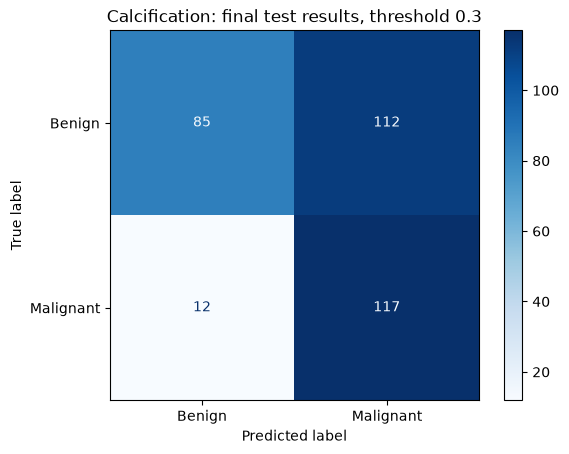

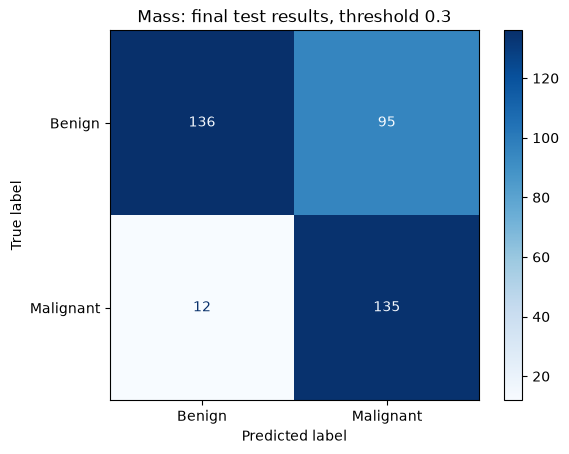

,Threshold,Test rows,Malignant proportion,Always-benign accuracy,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision,False negatives,False positives,False negative rate,False positive rate
Dataset,,,,,,,,,,,,,,
Calcification,0.3,326,0.396,0.604,0.620,0.511,0.907,0.654,0.783,0.712,12,112,0.093,0.569
Mass,0.3,378,0.389,0.611,0.717,0.587,0.918,0.716,0.838,0.722,12,95,0.082,0.411


In [20]:
label_mapping = {
    "MALIGNANT": 1,
    "BENIGN": 0,
    "BENIGN_WITHOUT_CALLBACK": 0,
}

final_test_results = []
final_test_predictions = {}

# Specify each final model, its input columns, and its fixed decision threshold.
test_jobs = [
    (
        "Calcification",
        final_calc_model,
        case_train,
        case_test,
        final_calc_features,
        0.3,
    ),
    (
        "Mass",
        final_mass_model,
        mass_train,
        mass_test,
        mass_features,
        0.3,
    ),
]

for name, fitted_model, training_data, test_data, columns, threshold in test_jobs:
    # Confirm test patients are separate from training patients.
    assert set(training_data["patient_id"]).isdisjoint(
        set(test_data["patient_id"])
    ), f"{name}: training/test patients overlap"

    answers = test_data["pathology"].map(label_mapping)
    assert answers.notna().all(), f"{name}: unexpected pathology label"
    assert answers.nunique() == 2, f"{name}: both classes are required"

    probabilities = fitted_model.predict_proba(
        test_data[columns]
    )[:, 1]

    # Scores become binary predictions using the threshold selected during development.
    predictions = (probabilities >= threshold).astype(int)

    # False negatives are malignant rows predicted benign; false positives are the reverse.
    tn, fp, fn, tp = confusion_matrix(
        answers, predictions, labels=[0, 1]
    ).ravel()

    final_test_results.append({
        "Dataset": name,
        "Threshold": threshold,
        "Test rows": len(answers),
        "Malignant proportion": answers.mean(),
        "Always-benign accuracy": (answers == 0).mean(),
        "Accuracy": accuracy_score(answers, predictions),
        "Precision": precision_score(
            answers, predictions, zero_division=0
        ),
        "Recall": recall_score(
            answers, predictions, zero_division=0
        ),
        "F1": f1_score(
            answers, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(answers, probabilities),
        "Average precision": average_precision_score(
            answers, probabilities
        ),
        "False negatives": fn,
        "False positives": fp,
        "False negative rate": fn / (fn + tp),
        "False positive rate": fp / (fp + tn),
    })

    # Keep row-level predictions for later review or export.
    prediction_table = test_data[["patient_id"]].copy()
    prediction_table["Actual label"] = answers.to_numpy()
    prediction_table["Malignancy probability"] = probabilities
    prediction_table["Predicted label"] = predictions
    final_test_predictions[name] = prediction_table

    ConfusionMatrixDisplay(
        confusion_matrix=np.array([[tn, fp], [fn, tp]]),
        display_labels=["Benign", "Malignant"],
    ).plot(cmap="Blues")

    plt.title(f"{name}: final test results, threshold {threshold}")
    plt.show()

final_test_summary = pd.DataFrame(
    final_test_results
).set_index("Dataset")

display(final_test_summary.round(3))

## Appendix: original single-split validation report

This evaluates the earlier five-feature baseline at threshold 0.5, not the final retrained models


Accuracy: 0.673
Precision: 0.536
Malignant recall: 0.541
F1: 0.539
ROC-AUC: 0.760
Average precision: 0.609
Always-benign accuracy: 0.647


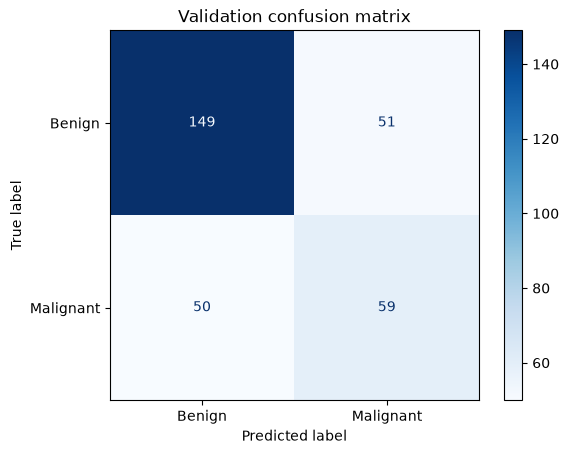

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

# Predicted probability of malignancy
val_probs = model.predict_proba(X_val)[:, 1]

# Probability >= 0.5 means malignant
val_preds = (val_probs >= 0.5).astype(int)

print(f"Accuracy: {accuracy_score(y_val, val_preds):.3f}")
print(f"Precision: {precision_score(y_val, val_preds, zero_division=0):.3f}")
print(f"Malignant recall: {recall_score(y_val, val_preds):.3f}")
print(f"F1: {f1_score(y_val, val_preds):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_val, val_probs):.3f}")
print(f"Average precision: {average_precision_score(y_val, val_probs):.3f}")

# Reference accuracy if we always predicted benign
print(f"Always-benign accuracy: {(y_val == 0).mean():.3f}")

cm = confusion_matrix(y_val, val_preds, labels=[0, 1])
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Benign", "Malignant"],
).plot(cmap="Blues")
plt.title("Validation confusion matrix")
plt.show()

## Appendix: table previews

These calls display the first five rows only. They do not train or evaluate models.


In [23]:
mass_test.head()

,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00016,4,LEFT,CC,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,Mass-Test_P_00016_LEFT_CC/1.3.6.1.4.1.9590.100...,Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Mass-Test_P_00016_LEFT_CC_1/1.3.6.1.4.1.9590.1...
1,P_00016,4,LEFT,MLO,1,mass,IRREGULAR,SPICULATED,5,MALIGNANT,5,Mass-Test_P_00016_LEFT_MLO/1.3.6.1.4.1.9590.10...,Mass-Test_P_00016_LEFT_MLO_1/1.3.6.1.4.1.9590....,Mass-Test_P_00016_LEFT_MLO_1/1.3.6.1.4.1.9590....
2,P_00017,2,LEFT,CC,1,mass,ROUND,CIRCUMSCRIBED,4,MALIGNANT,4,Mass-Test_P_00017_LEFT_CC/1.3.6.1.4.1.9590.100...,Mass-Test_P_00017_LEFT_CC_1/1.3.6.1.4.1.9590.1...,Mass-Test_P_00017_LEFT_CC_1/1.3.6.1.4.1.9590.1...
3,P_00017,2,LEFT,MLO,1,mass,ROUND,ILL_DEFINED,4,MALIGNANT,4,Mass-Test_P_00017_LEFT_MLO/1.3.6.1.4.1.9590.10...,Mass-Test_P_00017_LEFT_MLO_1/1.3.6.1.4.1.9590....,Mass-Test_P_00017_LEFT_MLO_1/1.3.6.1.4.1.9590....
4,P_00032,3,RIGHT,CC,1,mass,ROUND,OBSCURED,0,BENIGN,2,Mass-Test_P_00032_RIGHT_CC/1.3.6.1.4.1.9590.10...,Mass-Test_P_00032_RIGHT_CC_1/1.3.6.1.4.1.9590....,Mass-Test_P_00032_RIGHT_CC_1/1.3.6.1.4.1.9590....


In [34]:
mass_train.head()

,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....


## Working only with 'case' for this template. Duplicate for 'mass'

## Appendix: inspect calcification schema

Display column names and original pathology labels for reference. This is exploratory inspection rather than model evaluation.


In [35]:
# list all columns
print(case_train.columns)

# print unique values of pathology 
print(case_train['pathology'].unique())

Index(['patient_id', 'breast density', 'left or right breast', 'image view',
       'abnormality id', 'abnormality type', 'calc type', 'calc distribution',
       'assessment', 'pathology', 'subtlety', 'image file path',
       'cropped image file path', 'ROI mask file path'],
      dtype='str')
<StringArray>
['MALIGNANT', 'BENIGN', 'BENIGN_WITHOUT_CALLBACK']
Length: 3, dtype: str
